In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

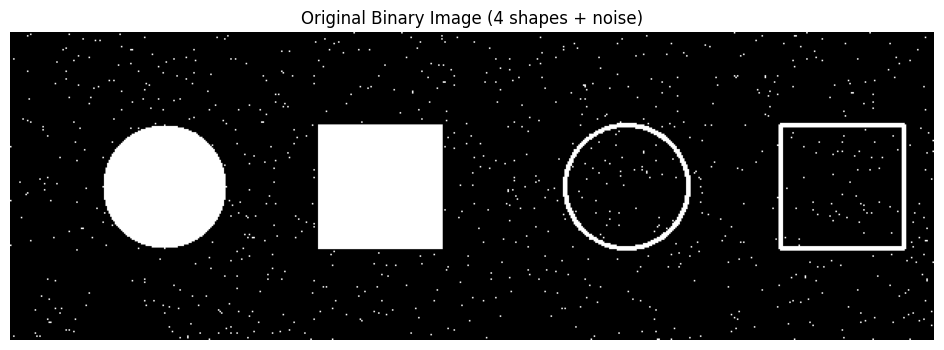

In [2]:
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


### Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

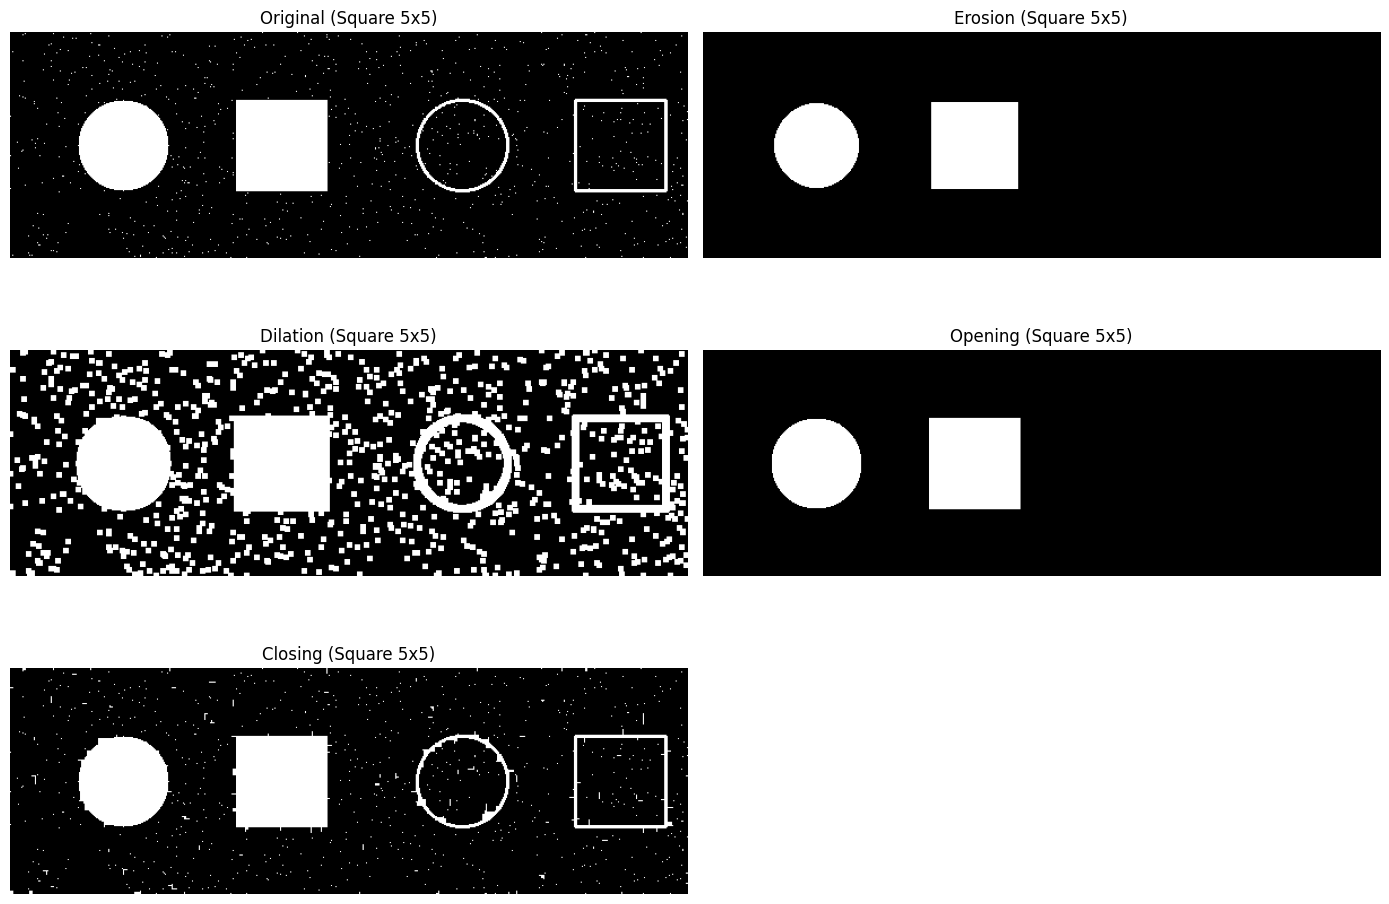

In [4]:
erosion  = cv2.erode(image, kernel, iterations=1)
dilation = cv2.dilate(image, kernel, iterations=1)
opening  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

results = [image, erosion, dilation, opening, closing]
titles  = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

plt.figure(figsize=(14, 10))
for i, (im, t) in enumerate(zip(results, titles)):
    plt.subplot(3, 2, i + 1)
    plt.imshow(im, cmap='gray')
    plt.title(t + ' (Square 5x5)')
    plt.axis('off')
plt.tight_layout()
plt.show()

### Assessment Task 2 — Repeat with a Circular Kernel

[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


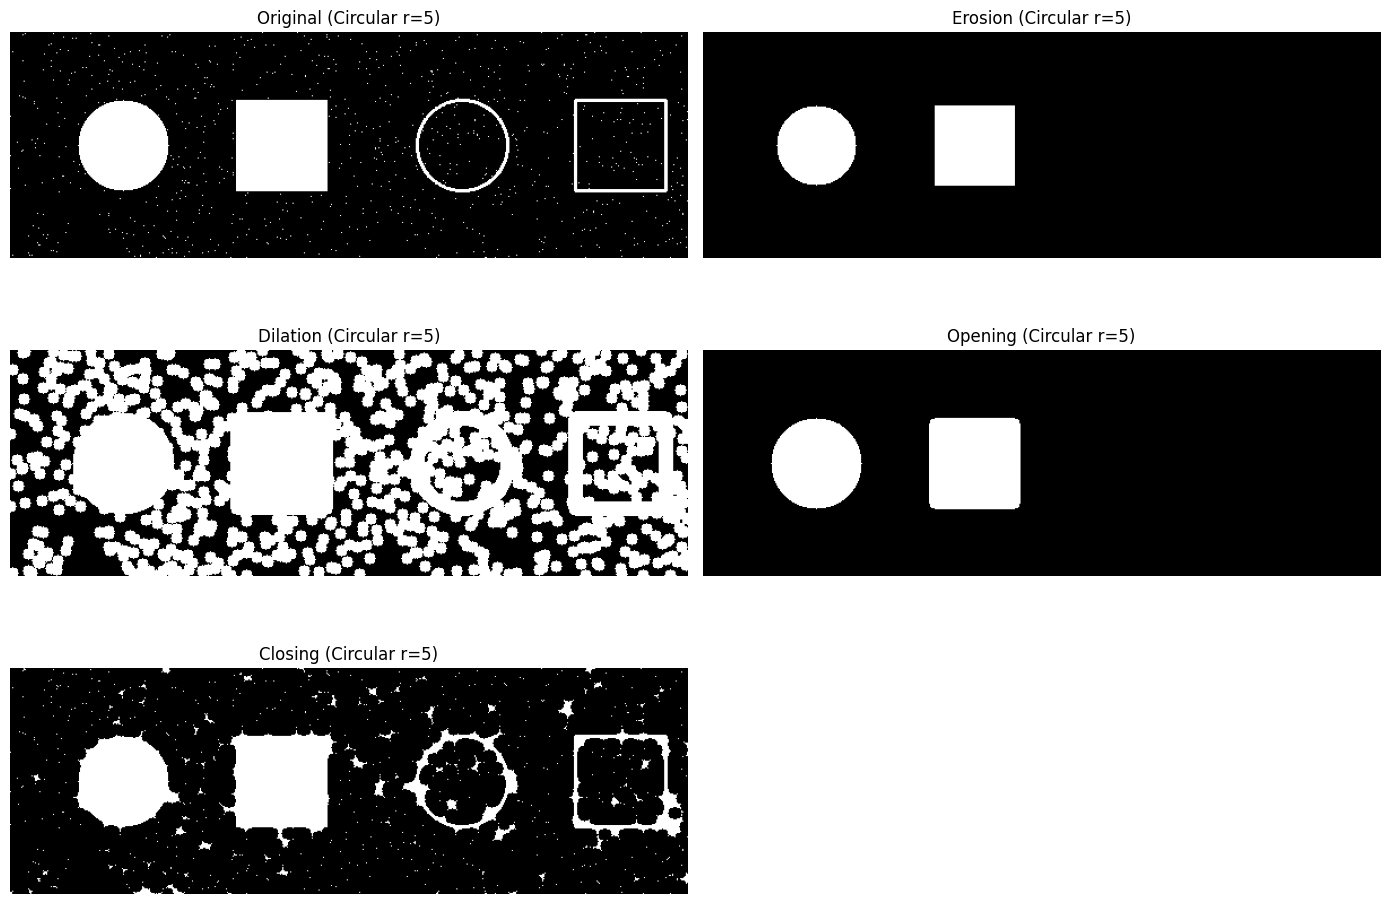

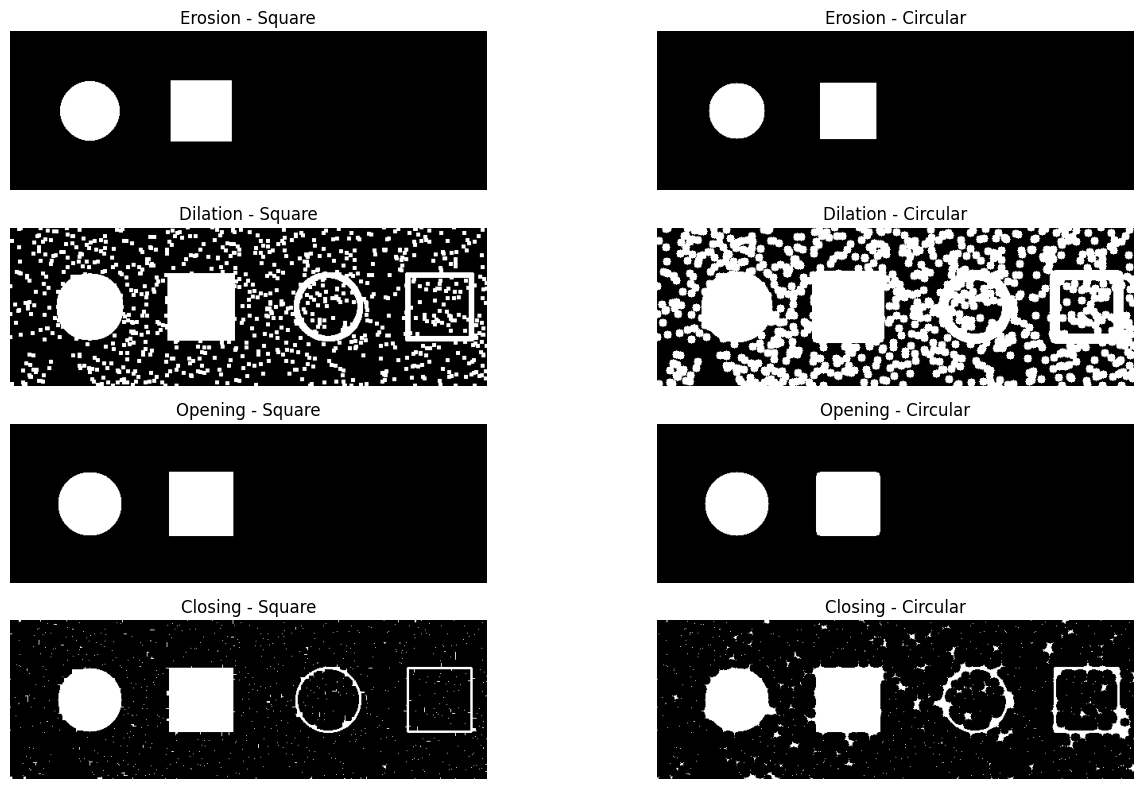

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)


print(circle_kernel)

erosion_c  = cv2.erode(image, circle_kernel, iterations=1)
dilation_c = cv2.dilate(image, circle_kernel, iterations=1)
opening_c  = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_c  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

results_c = [image, erosion_c, dilation_c, opening_c, closing_c]

plt.figure(figsize=(14, 10))
for i, (im, t) in enumerate(zip(results_c, titles)):
    plt.subplot(3, 2, i + 1)
    plt.imshow(im, cmap='gray')
    plt.title(t + ' (Circular r=5)')
    plt.axis('off')
plt.tight_layout()
plt.show()

# Side-by-side comparison of square vs circular
plt.figure(figsize=(14, 8))
pairs = [(erosion, erosion_c, 'Erosion'), (dilation, dilation_c, 'Dilation'),
         (opening, opening_c, 'Opening'), (closing, closing_c, 'Closing')]
for i, (s, c, t) in enumerate(pairs):
    plt.subplot(4, 2, 2*i + 1); plt.imshow(s, cmap='gray'); plt.title(t + ' - Square'); plt.axis('off')
    plt.subplot(4, 2, 2*i + 2); plt.imshow(c, cmap='gray'); plt.title(t + ' - Circular'); plt.axis('off')
plt.tight_layout()
plt.show()

### Assessment Task 3 — Difference Between Square vs Circular Kernel

in square kernel we can reaches farther along diagonals, so curved shapes get boxy. Corners of rectangles stay sharp. while in circular kernel  circles stay round but Rectangle corners get slightly rounded.

Erosion: both shrink the solid shapes and erase the thin hollow outlines.

Dilation: both grow the shapes. Square makes circles squarish, circular keeps them round.

Opening: both remove the noise and keep the solid shapes, but also delete the hollow shapes.

Closing: both fill small gaps but don't remove the noise. Hollow outlines survive and get a bit thicker.
